In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv("data/WA_Fn-UseC_-HR-Employee-Attrition.csv")
df = df.drop(columns=["EmployeeCount", "Over18", "StandardHours"])
saiu = df["Attrition"] == "Yes"


def mostra_p(p):
    return "p < 0,001" if p < 0.001 else f"p = {p:.3f}"

Salário mediano de quem saiu:  3,202
Salário mediano de quem ficou: 5,204
Mann-Whitney: p < 0,001


C:\Users\lucas\AppData\Local\Temp\ipykernel_7884\3230150984.py:10: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([ficaram, sairam], vert=False, widths=0.5, showfliers=False,


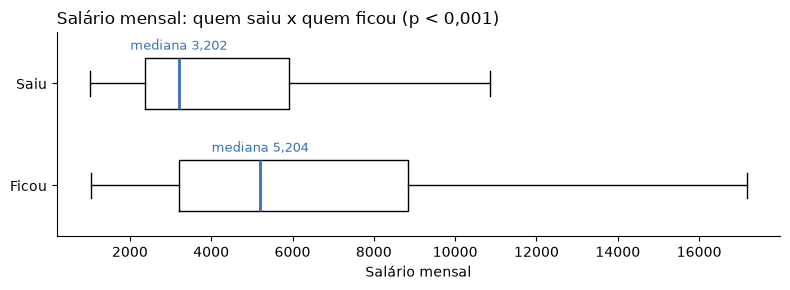

In [2]:
sairam = df.loc[saiu, "MonthlyIncome"]
ficaram = df.loc[~saiu, "MonthlyIncome"]

_, p = stats.mannwhitneyu(sairam, ficaram)
print(f"Salário mediano de quem saiu:  {sairam.median():,.0f}")
print(f"Salário mediano de quem ficou: {ficaram.median():,.0f}")
print(f"Mann-Whitney: {mostra_p(p)}")

fig, ax = plt.subplots(figsize=(8, 3))
ax.boxplot([ficaram, sairam], vert=False, widths=0.5, showfliers=False,
           medianprops={"color": "#3b6fb6", "linewidth": 2})
ax.set_yticks([1, 2], ["Ficou", "Saiu"])
for i, grupo in enumerate([ficaram, sairam], start=1):
    ax.text(grupo.median(), i + 0.33, f"mediana {grupo.median():,.0f}",
            ha="center", fontsize=9, color="#3b6fb6")
ax.set_title(f"Salário mensal: quem saiu x quem ficou ({mostra_p(p)})", loc="left")
ax.set_xlabel("Salário mensal")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Attrition   No  Yes
OverTime           
No         944  110
Yes        289  127

Qui-quadrado: p < 0,001 | V de Cramér: 0.24


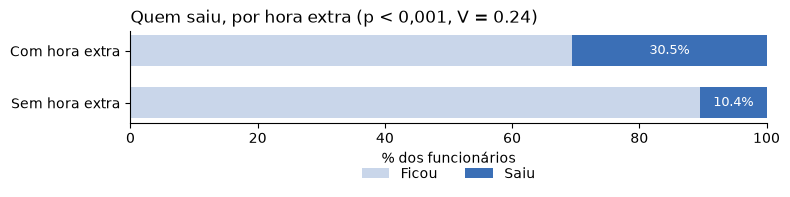

In [3]:
tabela = pd.crosstab(df["OverTime"], df["Attrition"])
chi2, p, _, _ = stats.chi2_contingency(tabela)
v = np.sqrt(chi2 / (tabela.values.sum() * (min(tabela.shape) - 1)))
print(tabela)
print(f"\nQui-quadrado: {mostra_p(p)} | V de Cramér: {v:.2f}")

pct = pd.crosstab(df["OverTime"], df["Attrition"], normalize="index").mul(100)
pct = pct.rename(index={"No": "Sem hora extra", "Yes": "Com hora extra"})

fig, ax = plt.subplots(figsize=(8, 2.4))
ax.barh(pct.index, pct["No"], color="#c9d6ea", height=0.6, label="Ficou")
ax.barh(pct.index, pct["Yes"], left=pct["No"], color="#3b6fb6", height=0.6, label="Saiu")
for i, (ficou, saiu_pct) in enumerate(zip(pct["No"], pct["Yes"])):
    ax.text(ficou + saiu_pct / 2, i, f"{saiu_pct:.1f}%", ha="center", va="center",
            color="white", fontsize=9)
ax.set_title(f"Quem saiu, por hora extra ({mostra_p(p)}, V = {v:.2f})", loc="left")
ax.set_xlim(0, 100)
ax.set_xlabel("% dos funcionários")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=2, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [4]:
numericas = {"MonthlyIncome": "Salário mensal", "YearsAtCompany": "Anos de casa",
             "Age": "Idade", "DistanceFromHome": "Distância de casa (km)"}
categoricas = {"OverTime": "Hora extra", "JobRole": "Cargo", "MaritalStatus": "Estado civil",
               "BusinessTravel": "Viagens a trabalho", "Department": "Área", "Gender": "Gênero"}

linhas = []
for col, nome in numericas.items():
    _, p = stats.mannwhitneyu(df.loc[saiu, col], df.loc[~saiu, col])
    linhas.append({"fator": nome, "teste": "Mann-Whitney",
                   "mediana saiu": df.loc[saiu, col].median(),
                   "mediana ficou": df.loc[~saiu, col].median(),
                   "V de Cramér": "", "p_num": p})
for col, nome in categoricas.items():
    t = pd.crosstab(df[col], df["Attrition"])
    chi2, p, _, _ = stats.chi2_contingency(t)
    v = np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))
    linhas.append({"fator": nome, "teste": "Qui-quadrado",
                   "mediana saiu": "", "mediana ficou": "",
                   "V de Cramér": round(v, 2), "p_num": p})

resumo = pd.DataFrame(linhas)
resumo["significativo?"] = np.where(resumo["p_num"] < 0.05, "sim", "não")
resumo["p"] = resumo["p_num"].apply(mostra_p)
resumo.drop(columns="p_num")

,fator,teste,mediana saiu,mediana ficou,V de Cramér,significativo?,p
0,Salário mensal,Mann-Whitney,3202.0,5204.0,,sim,"p < 0,001"
1,Anos de casa,Mann-Whitney,3.0,6.0,,sim,"p < 0,001"
2,Idade,Mann-Whitney,32.0,36.0,,sim,"p < 0,001"
3,Distância de casa (km),Mann-Whitney,9.0,7.0,,sim,p = 0.002
4,Hora extra,Qui-quadrado,,,0.24,sim,"p < 0,001"
5,Cargo,Qui-quadrado,,,0.24,sim,"p < 0,001"
6,Estado civil,Qui-quadrado,,,0.18,sim,"p < 0,001"
7,Viagens a trabalho,Qui-quadrado,,,0.13,sim,"p < 0,001"
8,Área,Qui-quadrado,,,0.09,sim,p = 0.005
9,Gênero,Qui-quadrado,,,0.03,não,p = 0.291


## Achados dos testes

- **Salário**: quem saiu tem salário mediano de 3.202, contra 5.204 de quem ficou. A diferença é significativa (Mann-Whitney, p < 0,001).
- **Hora extra**: a relação com a saída é significativa (qui-quadrado, p < 0,001) e é a mais forte entre os fatores testados (V de Cramér = 0,24), empatada com o cargo.
- **Tempo de casa e idade**: quem saiu tinha mediana de 3 anos de casa (contra 6) e 32 anos de idade (contra 36), ambos com p < 0,001.
- **Estado civil e viagens a trabalho** também têm relação significativa, mas mais fraca (V de 0,18 e 0,13).
- **Área** é significativa, mas com efeito pequeno (V = 0,09): o que pesa é o cargo, não o departamento.
- **Gênero não faz diferença** (p = 0,291): homens e mulheres saem na mesma proporção.

Conclusão: os padrões vistos na EDA não são obra do acaso. Hora extra, salário baixo e pouco tempo de casa são os sinais mais consistentes de risco de saída.